## Possible features to add

In [5]:
# importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

# importing the data
df = pd.read_csv('consumption_temp.csv')
df.head(10)

,time,location,consumption,temperature
0,2022-04-07 21:00:00,bergen,1.113325,-0.3
1,2022-04-07 21:00:00,oslo,4.092830,1.0
2,2022-04-07 21:00:00,stavanger,2.057858,1.3
3,2022-04-07 21:00:00,tromsø,1.246582,-3.9
4,2022-04-07 21:00:00,trondheim,1.970098,-2.8
5,2022-04-07 22:00:00,bergen,1.050327,0.0
6,2022-04-07 22:00:00,oslo,3.818095,0.4
7,2022-04-07 22:00:00,stavanger,1.918996,0.8
8,2022-04-07 22:00:00,tromsø,1.180321,-4.3
9,2022-04-07 22:00:00,trondheim,1.839443,-3.3


In [6]:
# setting the date as index
df = df.set_index(pd.to_datetime(df['time'])).drop(columns='time')

In [7]:
# need to have time local time for each area
df.index = df.index.tz_localize('UTC')   
tz = {'helsingfors': 'Europe/Helsinki'}  

parts = []
for loc, g in df.groupby('location'):
    t = g.index.tz_convert(tz.get(loc, 'Europe/Oslo'))
    parts.append(g.assign(hour=t.hour, dow=t.dayofweek, local_date=t.normalize().tz_localize(None)))
df = pd.concat(parts).sort_index()
import holidays

cal = {'helsingfors': holidays.Finland(years=[2022, 2023])}
default_cal = holidays.Norway(years=[2022, 2023])

df['is_holiday'] = [
    d in cal.get(loc, default_cal)
    for d, loc in zip(df['local_date'], df['location'])
]

# is_off = holidays or weekends
df['is_off'] = (df['is_holiday'] | (df['dow'] >= 5)).astype(int)
df['day_of_week'] = df['dow']
df= df.drop(columns='dow')

### Temperature's features
* daily min/max and avarage 
* difference between today forcats and the average of the last 7 days 
* difference between with 24h ago
* rolling mean
* cold index

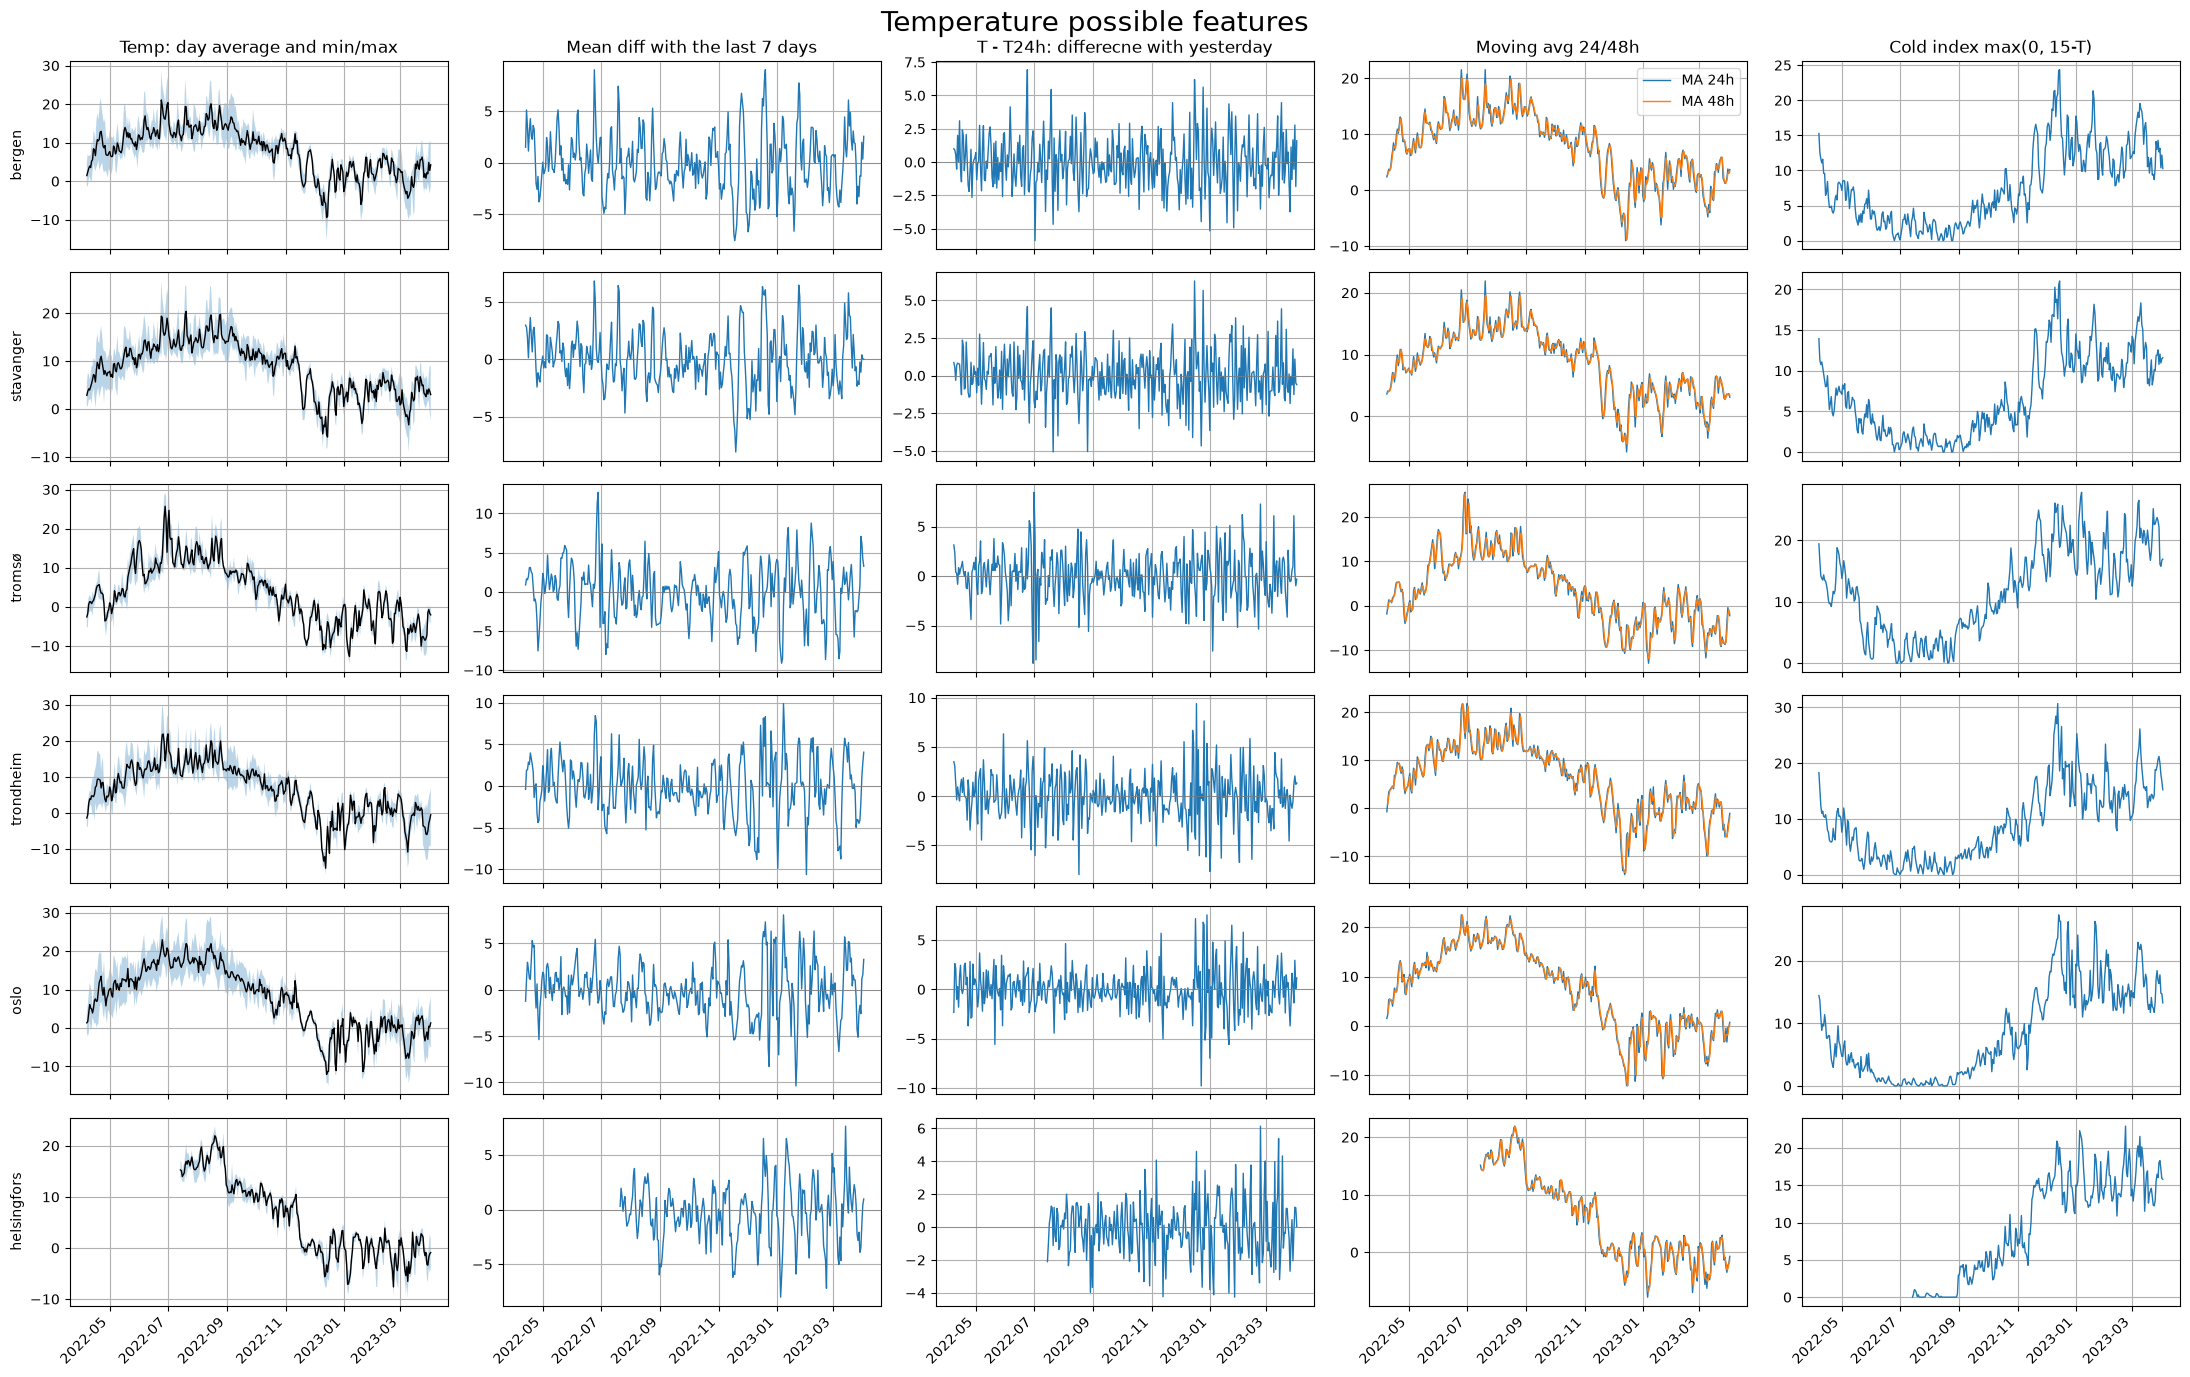

In [8]:
# compute the temperature fetures
def temp_feats(d):
    d = d.sort_index().copy()
    T = d['temperature']
    g = T.groupby(d['local_date'])
    d['t_min'], d['t_max'], d['t_mean'] = g.transform('min'), g.transform('max'), g.transform('mean')

    # difference with the average temp of the last seven days
    daily = g.mean()
    recent = daily.shift(1).rolling(7).mean()
    d['t_anom'] = T - d['local_date'].map(recent).values

    # variaton between yesterday (same hour)
    d['t_d24'] = T - T.shift(24)
    
    # rolling means
    d['t_ma24'] = T.rolling(24).mean()
    d['t_ma48'] = T.rolling(48).mean()
    
    # cold index
    d['cold'] = np.maximum(0, 15 - T)    
    return d

# plot
cities = df['location'].unique()
fig, ax = plt.subplots(len(cities), 5, figsize=(22, 14), sharex=True)

for i, city in enumerate(cities):
    d = temp_feats(df[df['location'] == city])
    # daily means
    D = d.tz_localize(None).resample('D').mean(numeric_only=True) 

    ax[i, 0].plot(D.index, D['t_mean'], color='k', lw=1)
    ax[i, 0].fill_between(D.index, D['t_min'], D['t_max'], alpha=.3)
    ax[i, 1].plot(D['t_anom'], lw=1); ax[i, 1].axhline(0, color='gray', lw=.5)
    ax[i, 2].plot(D['t_d24'], lw=1);  ax[i, 2].axhline(0, color='gray', lw=.5)
    ax[i, 3].plot(D['t_ma24'], label='MA 24h', lw=1); ax[i, 3].plot(D['t_ma48'], label='MA 48h', lw=1)
    ax[i, 4].plot(D['cold'], lw=1)
    ax[i, 0].set_ylabel(city)
    for a in ax[i]: a.grid()

# set the columns title
for a, t in zip(ax[0], ['Temp: day average and min/max', 'Mean diff with the last 7 days',
                        'T - T24h: differecne with yesterday', 'Moving avg 24/48h', 'Cold index max(0, 15-T)']):
    a.set_title(t)

ax[0, 3].legend()
fig.autofmt_xdate(rotation=45, ha='right')
fig.suptitle('Temperature possible features', fontsize=20)
plt.tight_layout()
plt.show()

In [9]:
d = df.copy()
d['lvl'] = d.groupby('location')['consumption'].transform(lambda s: s.shift(120).rolling(24*7).mean())
d['y'] = d['consumption'] / d['lvl']
for th in (10, 12, 15, 18):
    d['c'] = np.maximum(0, th - d['temperature'])
    print(th, d.groupby('location', observed=True).apply(lambda g: g['c'].corr(g['y'])).round(2).to_dict())

10 {'bergen': 0.14, 'helsingfors': -0.25, 'oslo': 0.12, 'stavanger': 0.13, 'tromsø': 0.14, 'trondheim': 0.21}
12 {'bergen': 0.13, 'helsingfors': -0.28, 'oslo': 0.11, 'stavanger': 0.1, 'tromsø': 0.15, 'trondheim': 0.2}
15 {'bergen': 0.13, 'helsingfors': -0.33, 'oslo': 0.1, 'stavanger': 0.08, 'tromsø': 0.17, 'trondheim': 0.21}
18 {'bergen': 0.14, 'helsingfors': -0.34, 'oslo': 0.08, 'stavanger': 0.08, 'tromsø': 0.18, 'trondheim': 0.21}


### Consumption's features
* dayily average of 5 days ago
* moving average (starting form 5 days earlier)
    * trend level moving avg 3 days window / moving avg 14 days window

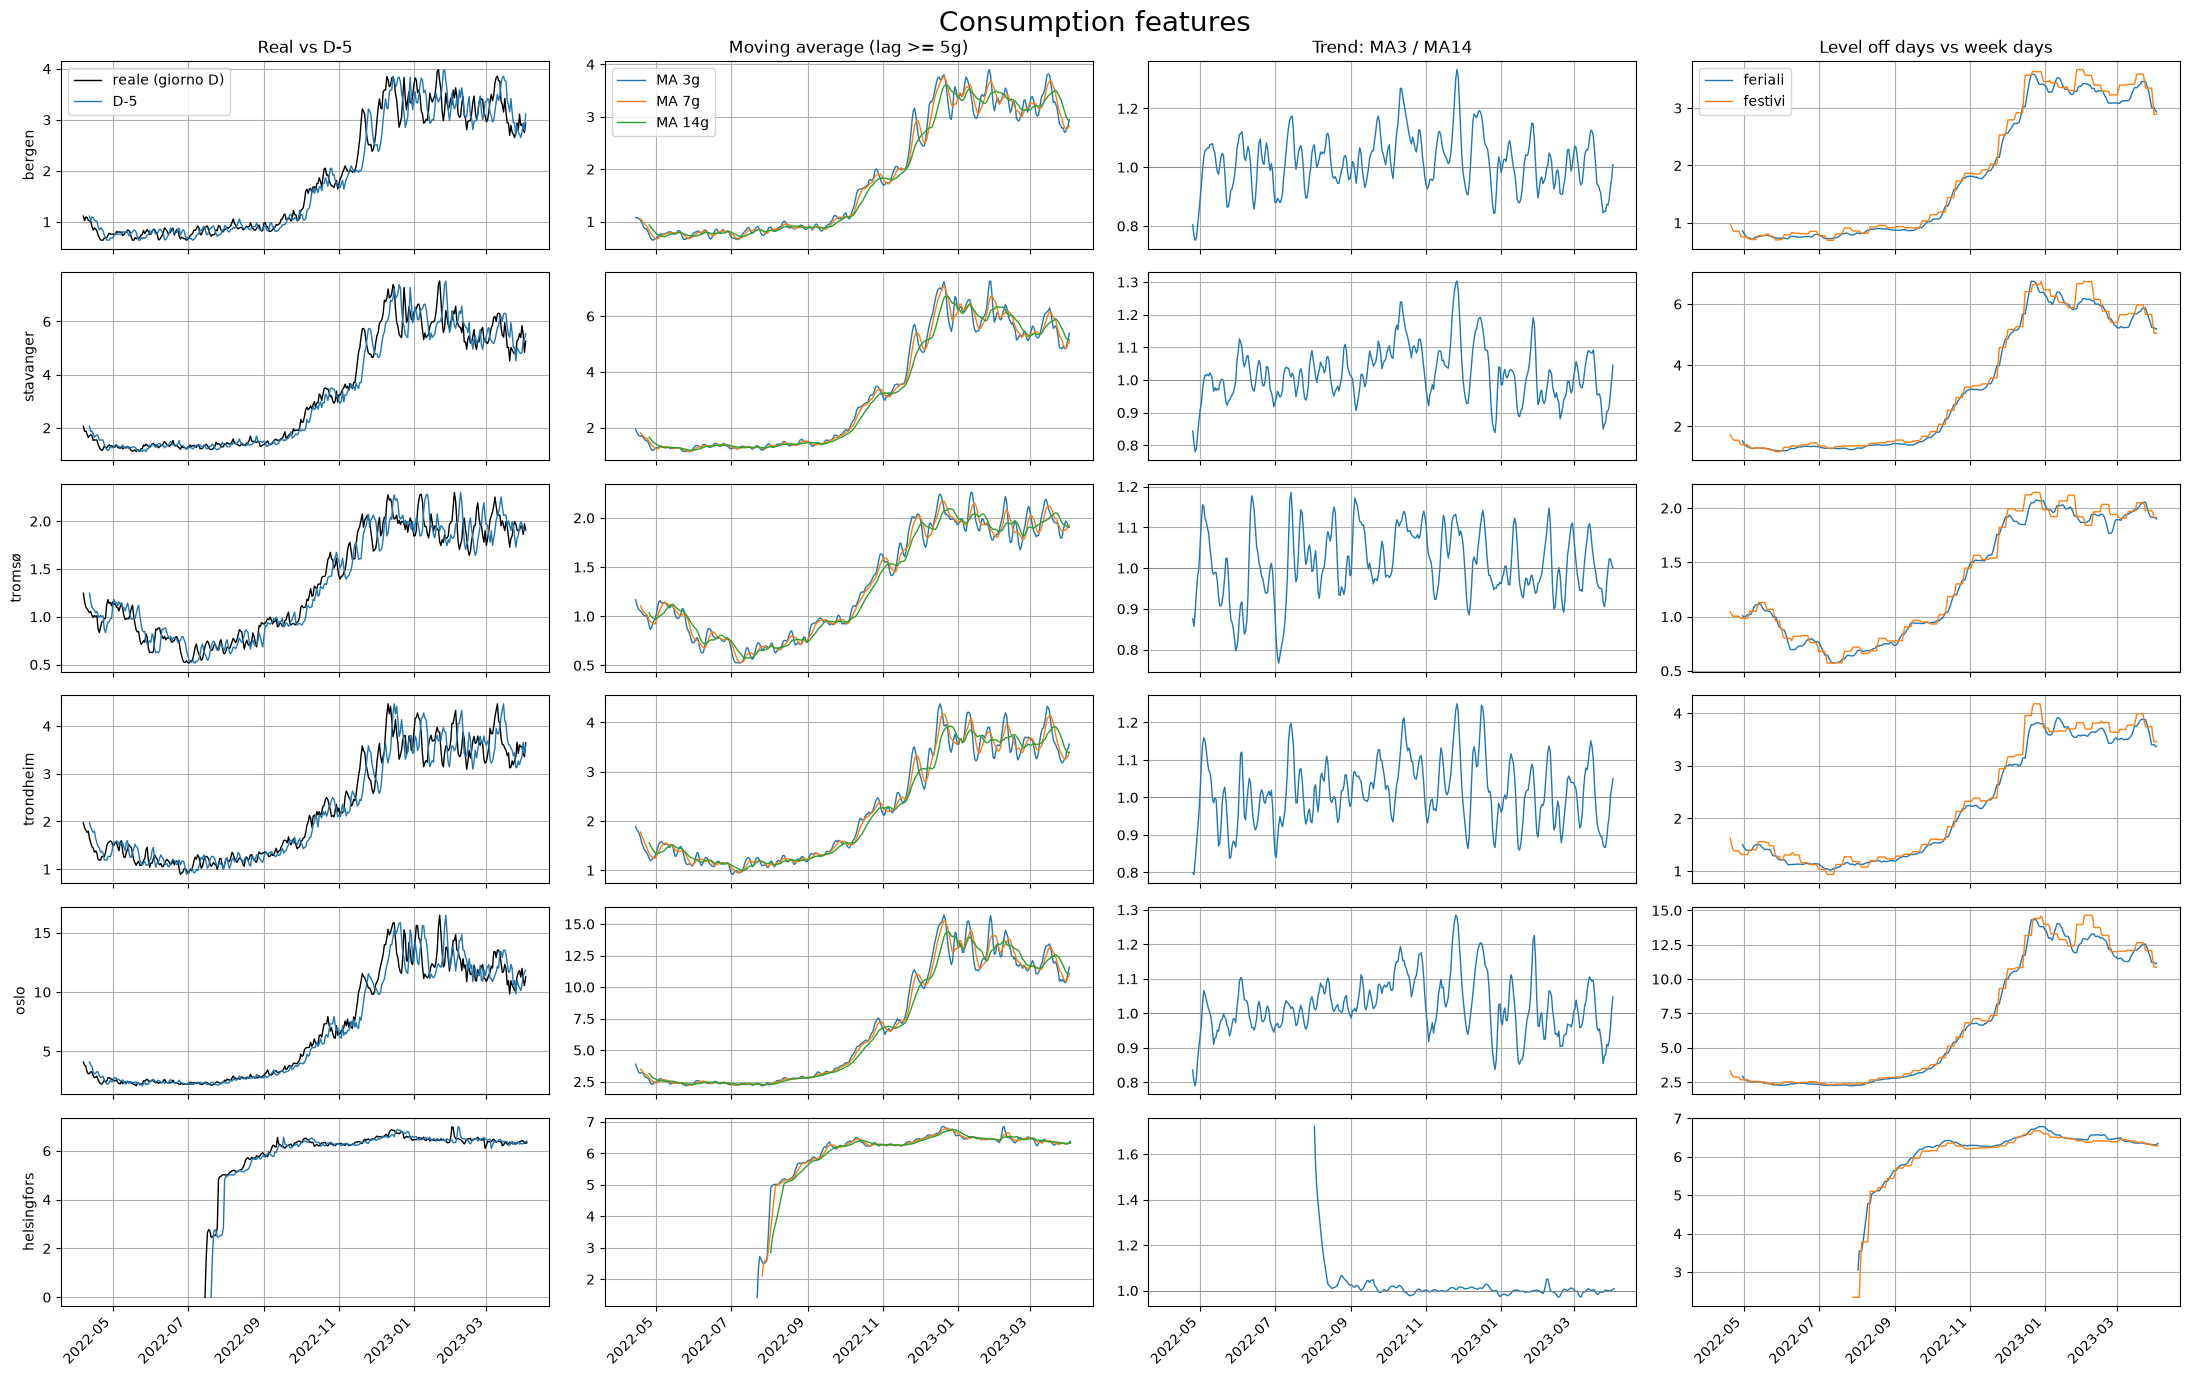

In [10]:
# 
def lvl_type(day, off, k):
    # get the last 5 days of the same type (week/off days)
    s = day.loc[day['off'] == off, 'c'].rolling(k).mean()  
    
    # 5 days lag
    return s.reindex(day.index).ffill().shift(5)        

#plot
fig, ax = plt.subplots(len(cities), 4, figsize=(22, 14), sharex=True)
for i, city in enumerate(cities):
    d = df[df['location'] == city]
    day = d.groupby('local_date').agg(c=('consumption', 'mean'), off=('is_off', 'first'))
    lag = day['c'].shift(5)
    ma = {k: lag.rolling(k).mean() for k in (3, 7, 14)}

    ax[i, 0].plot(day['c'], color='k', lw=1, label='reale (giorno D)')
    ax[i, 0].plot(lag, lw=1, label='D-5')
    for k in (3, 7, 14):
        ax[i, 1].plot(ma[k], lw=1, label=f'MA {k}g')
    ax[i, 2].plot(ma[3] / ma[14], lw=1); ax[i, 2].axhline(1, color='gray', lw=.5)
    lw_, lo_ = lvl_type(day, 0, 10), lvl_type(day, 1, 4)
    ax[i, 3].plot(lw_, lw=1, label='feriali'); ax[i, 3].plot(lo_, lw=1, label='festivi')
    ax[i, 0].set_ylabel(city)
    for a in ax[i]: a.grid()

# give name
for a, t in zip(ax[0], ['Real vs D-5', 'Moving average (lag >= 5g)', 'Trend: MA3 / MA14', 'Level off days vs week days']):
    a.set_title(t)
    
# give legend
for a in (ax[0, 0], ax[0, 1], ax[0, 3]): a.legend()

fig.suptitle('Consumption features', fontsize=20)
fig.autofmt_xdate(rotation=45, ha='right')
plt.tight_layout(); plt.show()